### IPD441 - Visión por Computador
# Clase 14: Stable Diffusion
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Diffusion

Todos los modelos generativos de imágenes recientes están basados en el mismo mecanismo: "diffusion". El cual, recibe como entrada ruido aleatorio, aunque puede condicionarse con un texto o una imagen, y aprende de forma iterativa a eliminar este ruido. Sin embargo, este proceso es muy costoso ya que trabaja directamente sobre los pixeles de la imagen.

<div align="center">
    <img src="img/reverse_diffusion.jpg" alt="" width="80%" align="center" />
</div>

## ¿Cómo lograr eficiencia? 

Transformándolos en modelos de difusión latente. Esto significa trabajar con una representación de imagen comprimida. Por lo tanto, ya no se trabaja sobre el espacio de píxeles ni con las imágenes originales, sino con una representación latente.

<div align="center">
    <img src="img/latent_representation.png" alt="" width="50%" align="center" />
</div>

# Latent Diffusion Models (LDMs)

En 2021, el artículo ["High-Resolution Image Synthesis with Latent Diffusion Models"](https://arxiv.org/pdf/2112.10752.pdf) propone una mejora eficiente y flexible en los modelos de difusión para la generación de imágenes de alta resolución, utilizando el espacio latente de autoencoders preentrenados y mejorando la arquitectura mediante capas de atención cruzada.

<div align="center">
    <img src="img/LDM.png" alt="" width="50%" align="center" />
</div>

# Resumen de componentes de LDM

| Componente | Descripción |
|---|---|
| VAE | Codifica/decodifica imagen ⇄ espacio latente. |
| U-Net de difusión | Predice el ruido en espacio latente, modelando la generación. |
| Text Encoder (CLIP) | Codifica el texto a embeddings para el cross-attention. |
| Cross-Attention | Permite condicionar la generación en múltiples capas del U-Net. |

In [2]:
import matplotlib.pyplot as plt

In [3]:
# pip install transformers==4.35.2 --quiet

In [4]:
from diffusers import DiffusionPipeline

In [ ]:
ldm = DiffusionPipeline.from_pretrained("CompVis/ldm-text2im-large-256")

In [6]:
def plot_images(images):
    total_images = len(images)
    if total_images < 2:
        plt.figure(figsize=(4, 4))
        plt.imshow(images[0])
        plt.axis('off')
    else:
        fig, axes = plt.subplots(1, 
                                 total_images, 
                                 figsize=(4*total_images, 4))
        for i in range(total_images):
            axes[i].imshow(images[i])
            axes[i].axis('off')
        plt.tight_layout()
    plt.show()

In [6]:
def text2img(model, prompt, n = 3, steps = 50, guidance=6, eta=0.0, seed=123):
    imgs = ldm(prompt=[prompt]*n, 
               # The number of denoising steps. More denoising steps usually
               # lead to a higher quality image at the expense of slower inference.
               num_inference_steps=steps,
               # A higher guidance scale value encourages the model to generate images
               # closely linked to the text `prompt` at the expense of lower image quality.
               guidance_scale=guidance,  
               num_images_per_prompt=n,
               prng_seed=seed,
               eta=eta
              ).images
    plot_images(imgs)

  0%|          | 0/50 [00:00<?, ?it/s]

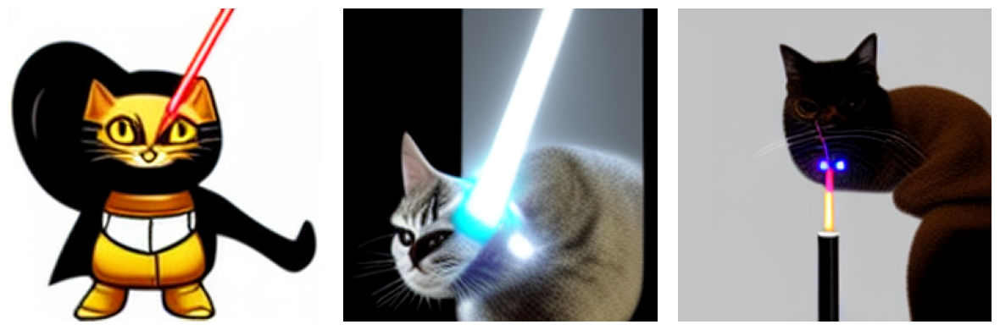

In [7]:
text2img(ldm, "A Master Jedi Cat Holding A Light Saber", n = 3, steps = 50)

# Stable Diffusion (2022)

Stable Diffusion v1 es un modelo de difusión latente. No trabaja directamente en el espacio de píxeles (como DDPM clásicos) sino en un espacio latente comprimido más pequeño y eficiente.

<div align="center">
    <img src="img/Stable_Diffusion_architecture.jpg" alt="" width="50%" align="center" />
</div>

# Proceso de difusión de SD

<div align="right">
    <img src="img/Stable_Diffusion_Process.png" alt="" width="60%" align="right" />
</div>

Durante el entrenamiento, el Encoder convierte imágenes reales en representaciones latentes. Se añade ruido progresivamente y se entrena la UNet para predecir ese ruido. El modelo aprende a revertir el proceso de difusión paso a paso.

Se parte de ruido aleatorio ($z_T$). A través de múltiples pasos ($T$ veces), la UNet predice y elimina ruido gradualmente. El proceso está condicionado por texto, mapas semánticos u otros inputs ($τ_θ$). Finalmente, el Decoder convierte la representación latente limpia en una imagen final.


In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

In [2]:
import tensorflow as tf
tf.get_logger().setLevel(tf.compat.v1.logging.ERROR)

In [3]:
#pip install numpy==1.26.3
#!pip install tensorflow==2.15.0
#pip install keras==3.0.0
#!pip install keras-cv==0.8.1

In [4]:
import tensorflow as tf
import keras
import numpy as np
import keras_cv
import sys

print("Python version:",sys.version)
print("Numpy version:",np.__version__)
print("Keras version:",keras.__version__)
print("TensorFlow version:",tf.__version__)
print("Keras-CV version:",keras_cv.__version__)

Python version: 3.10.12 (main, Jul  5 2023, 15:34:07) [Clang 14.0.6 ]
Numpy version: 1.26.3
Keras version: 3.0.0
TensorFlow version: 2.15.0
Keras-CV version: 0.8.1


In [5]:
import matplotlib.pyplot as plt
from keras_cv.models import StableDiffusion, StableDiffusionV2
from PIL import Image

In [6]:
sd = StableDiffusion(img_height=512, img_width=512, jit_compile=True)

By using this model checkpoint, you acknowledge that its usage is subject to the terms of the CreativeML Open RAIL-M license at https://raw.githubusercontent.com/CompVis/stable-diffusion/main/LICENSE


In [7]:
def generate(model, prompt, n = 3, steps = 25, seed = 123):
    images = model.text_to_image(
        prompt=prompt,
        batch_size=n,  # How many images to generate at once
        num_steps=steps,  # Number of iterations (controls image quality)
        seed=seed,  # Set this to always get the same image from the same prompt
    )
    plot_images(images)

25/25 ━━━━━━━━━━━━━━━━━━━━ 2237s 89s/step


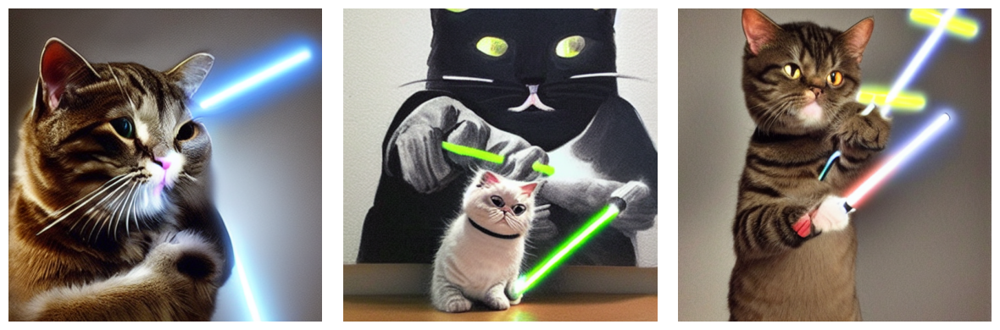

In [9]:
generate(sd, "A Master Jedi Cat Holding A Light Saber", n = 3, steps = 25)

# Stable Diffusion v2

La arquitectura base sigue siendo similar (VAE + U-Net + Condicionamiento textual), pero con varias mejoras importantes.

- VAE mejorado con mejor calidad y capacidad para para resoluciones 768×768 (no solo 512×512).
- U-Net expandido y refinado con técnicas de "multi-conditioning".
- Nuevo Text Encoder: OpenCLIP. 

# OpenCLIP

OpenCLIP es una implementación open-source del modelo CLIP de OpenAI, pero:

- Entrenado sobre datasets aún más grandes (como LAION-2B, LAION-Aesthetics).

- Arquitectura basada en Vision Transformer (ViT-H/14):

    - "H" indica una versión mucho más grande que ViT-B usada en CLIP original.

    - "14" es el tamaño de patch en píxeles.

- Mejora la calidad de comprensión semántica de frases complejas y matices de lenguaje.

- Permite prompts más largos y descriptivos que tienen mejor correlación con las imágenes finales.

# Comparativa: SD v1 vs SD v2

| Característica | Stable Diffusion v1 | Stable Diffusion v2 |
|---|---|---|
| Dataset de entrenamiento | LAION-5B | LAION-Aesthetics |
| Resolución base | 512x512 | 768x768 |
| Encoder de Texto | CLIP (original) | OpenCLIP (mejorado) |
| Calidad anatómica | Baja | Mejorada |
| Consistencia visual | Moderada | Alta |
| Capacidades extendidas | No | Depth-to-Image, Inpainting |

In [8]:
sd2 = StableDiffusionV2(img_height=512, img_width=512, jit_compile=True)

By using this model checkpoint, you acknowledge that its usage is subject to the terms of the CreativeML Open RAIL++-M license at https://github.com/Stability-AI/stablediffusion/blob/main/LICENSE-MODEL


25/25 ━━━━━━━━━━━━━━━━━━━━ 1612s 64s/step


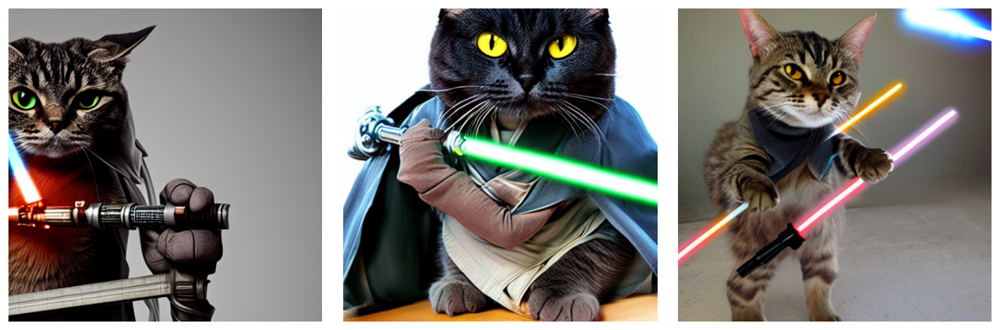

In [14]:
generate(sd2, "A Master Jedi Cat Holding A Light Saber", n = 3, steps = 25)

# Stable Diffusion XL (SDXL)

- Modelo más grande: ~2.6B parámetros (Base + Refiner).
- Entrenamiento en 3 fases: Base model → Refiner model → Fine-tuning.
- Arquitectura modular: UNet base genera latentes; UNet refiner mejora detalles.
- Espacio latente comprimido: VAE mejorado para mapear imágenes a latentes eficientes.
- Condicionamiento doble: Usa CLIP ViT-G/14 + embeddings extra para prompts largos.
- Mejor separación de estilo y contenido: Estilo afecta apariencia, no el contenido semántico.
- Mejor manejo de prompts largos y detallados: Captura múltiples conceptos simultáneamente.
- Reducción de artefactos visuales: Mejor calidad de rostros, manos y objetos pequeños.



# Arquitectura SDXL

<div align="center">
    <img src="img/sdxl.png" alt="" width="70%" align="center" />
</div>

In [1]:
from hive import *

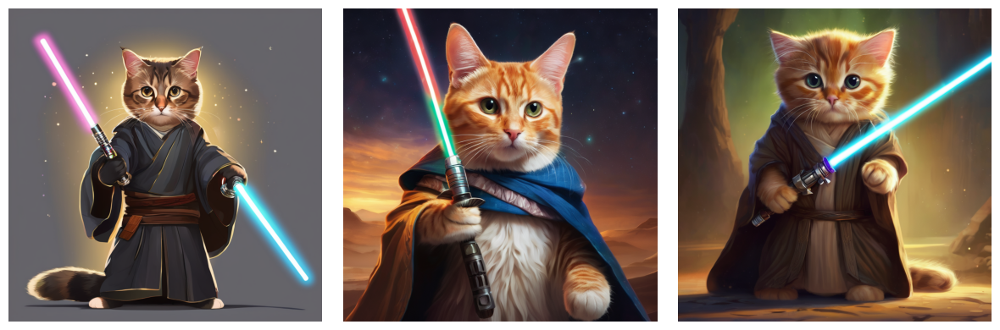

In [2]:
generar_imagen_hive(prompt="A Master Jedi Cat Holding A Light Saber", n=3)

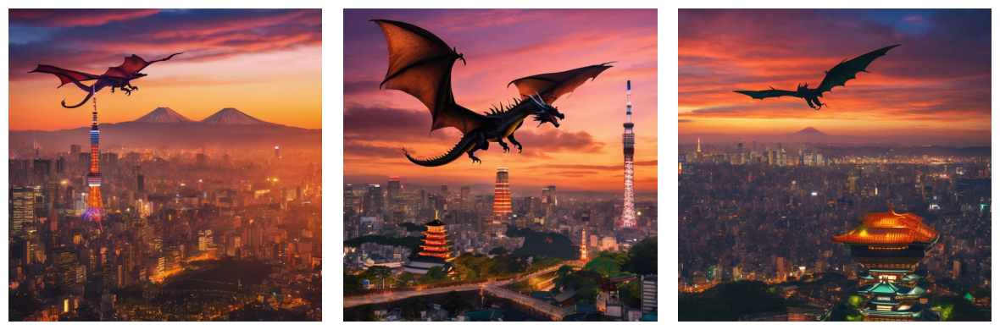

In [2]:
generar_imagen_hive(prompt="A dragon flying over Tokyo at sunset", n=3)

# The Latent Space

Los modelos de imágenes generativas aprenden un "latent manifold" del mundo visual: un espacio vectorial de baja dimensión donde cada punto se mapea a una imagen. Pasar de ese punto en el manifold a una imagen visualizable se llama "decodificación"; en el modelo Stable Diffusion, esto lo maneja el "decodificador".

<div align="center">
    <img src="img/latent_space.png" alt="" width="80%" align="center" />
</div>

# Exploring the Latent Space

Una "caminata por el espacio latente", o "exploración del espacio latente", es el proceso de muestrear un punto en el espacio latente y cambiar gradualmente la representación latente. 

In [9]:
from keras import ops
import math

In [10]:
def interpolation(model, prompt_1, prompt_2, interpolation_steps, steps=25, seed = 12345):
    encoding_1 = ops.squeeze(model.encode_text(prompt_1))
    encoding_2 = ops.squeeze(model.encode_text(prompt_2))

    interpolated_encodings = ops.linspace(encoding_1, encoding_2, interpolation_steps)
    noise = keras.random.normal((512 // 8, 512 // 8, 4), seed=seed)

    images = model.generate_image(
        interpolated_encodings,
        batch_size=interpolation_steps,
        diffusion_noise=noise,
        num_steps=steps,
    )
    return images

In [ ]:
# Stable Diffusion V1
interpolated_image = interpolation(sd, "A teddy bear with a tennis racket", 
                                   "Elmo with a shotgun", interpolation_steps = 5)

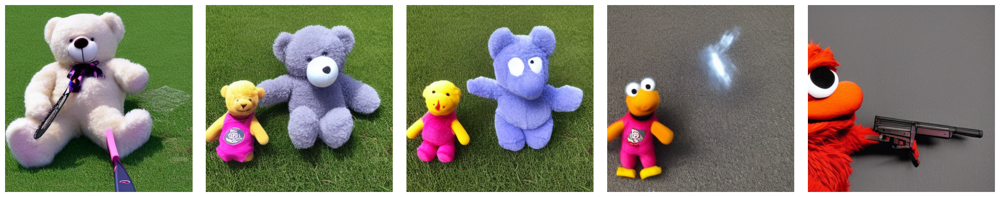

In [12]:
plot_images(interpolated_image)

In [ ]:
# Stable Diffusion 2
interpolated_image = interpolation(sd2, "A teddy bear with a tennis racket", 
                                   "Elmo with a shotgun", interpolation_steps = 5)

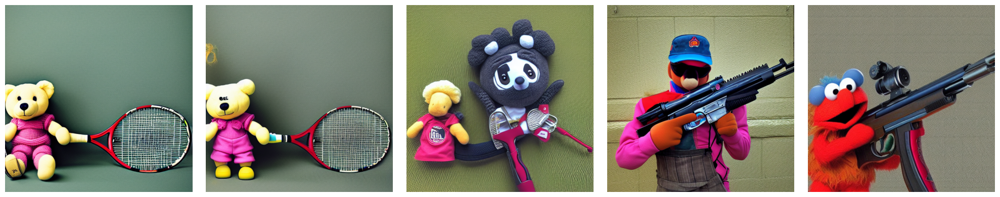

In [12]:
plot_images(interpolated_image)

# Image Variations

La generación de variaciones de una imagen mediante un modelo de difusión latente implica el muestreo en el espacio latente y la aplicación de un proceso de difusión que modela cómo evolucionan las características latentes para crear versiones modificadas de la imagen original. Este enfoque ofrece flexibilidad y control en la generación de imágenes, lo que lo hace valioso en tareas como la síntesis de alta resolución.

## Stable Diffusion Image Variations Model

Este modelo es un fine tuning de "Stable Diffusion v1-4", adaptado para aceptar CLIP image embeddings en lugar de text embeddings. Por lo tanto, el codificador de texto ha sido reemplazado por un codificador de imágenes. El procedimiento de entrenamiento es el mismo que para Stable Diffusion excepto por el hecho de que las imágenes se codifican a través de un codificador de imágenes ViT-L/14.

In [6]:
import torch
from PIL import Image
from torchvision import transforms
from diffusers import StableDiffusionImageVariationPipeline

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
sd_pipe = StableDiffusionImageVariationPipeline.from_pretrained(
  "lambdalabs/sd-image-variations-diffusers",
  revision="v2.0",
  )
sd_pipe = sd_pipe.to(device)

In [8]:
def img_variations(model, path, n=4):
    im = Image.open(path)
    out = model([im]*n, guidance_scale=3)
    plot_images([im]+out["images"])

  0%|          | 0/50 [00:00<?, ?it/s]

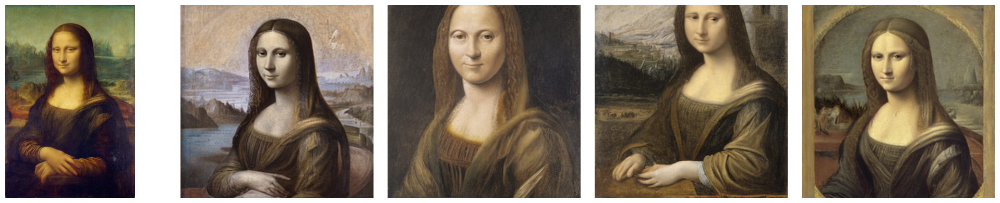

In [9]:
img_variations(sd_pipe, "test/gioconda.jpg", n=4)

  0%|          | 0/50 [00:00<?, ?it/s]

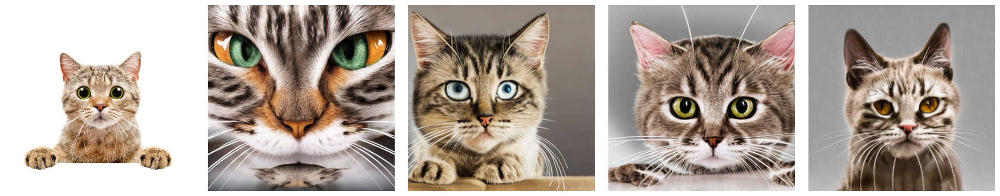

In [9]:
img_variations(sd_pipe, "test/cat.jpg", n=4)

  0%|          | 0/50 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


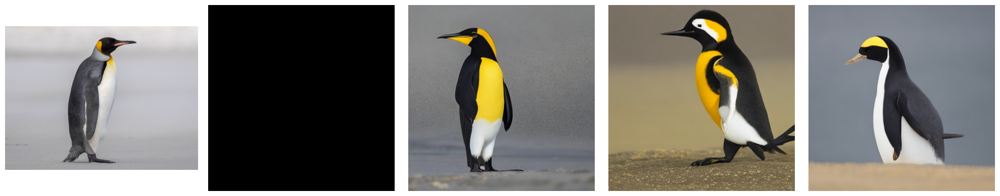

In [10]:
img_variations(sd_pipe, "test/penguin.jpeg", n=4)